# 1 · Your first analog program: from one atom to the Rydberg blockade

A neutral-atom QPU holds individual atoms in optical tweezers. Each atom is a qubit: the ground state $|g\rangle$ reads as `0`, a highly excited **Rydberg** state $|r\rangle$ reads as `1`. A global laser drives all atoms at once, and two Rydberg atoms interact strongly when they are close.

In **analog** mode you do not write gates. You write the Hamiltonian the atoms follow over time:

$$
\frac{H(t)}{\hbar} = \underbrace{\frac{\Omega(t)}{2}\sum_i \left(\cos\phi\,\sigma^x_i + \sin\phi\,\sigma^y_i\right)}_{\text{drive}} \;-\; \underbrace{\Delta(t)\sum_i n_i}_{\text{detuning}} \;+\; \underbrace{\sum_{i<j}\frac{C_6}{r_{ij}^6}\, n_i n_j}_{\text{interaction}}
$$

Here $\sigma^x_i$ and $\sigma^y_i$ are Pauli matrices acting on atom $i$, and $n_i$ counts whether atom $i$ is excited: 1 in `1`, 0 in `0`.

| Term | You control | Effect |
|---|---|---|
| Drive $\Omega(t)$, phase $\phi(t)$ | Laser amplitude and phase | Rotates each atom between `0` and `1` |
| Detuning $\Delta(t)$ | Laser frequency | Positive values favour `1` |
| Interaction $C_6/r^6$ | Atom positions | Two nearby `1`s cost energy |

In CUDA-Q this Hamiltonian is a `RydbergHamiltonian`, and `cudaq.evolve` runs it on the selected target: the GPU emulator, a QPU your scheduler assigned through QRMI, or Pasqal Cloud. In this notebook you will:

1. set the one physical constant the emulator needs, $C_6$,
2. write and run a program by hand, and read its result,
3. learn how CUDA-Q turns your pulse functions into a pulse,
4. launch many programs at once with `evolve_async`,
5. see two atoms behave independently, then discover the **Rydberg blockade**,
6. switch the same program to a QPU.

**CUDA-Q you will use:** `set_target`, `RydbergHamiltonian`, `ScalarOperator`, `Schedule`, `evolve`, `evolve_async`, `set_random_seed` and the `SampleResult` it returns.

Every cell runs live with CUDA-Q on an NVIDIA GPU (`pip install -e '.[gpu-cu13,notebook]'`, or `gpu-cu12` with a CUDA 12 driver; see the README). The whole notebook also runs top to bottom as is: the **Predict** and **Your turn** cells work with their defaults, so you can edit them or just run them.

**Predict** cells ask for your guess before a result; leave `None` to skip. **Check yourself** questions open with a click.

In [1]:
# Copyright 2026 Pasqal
# SPDX-License-Identifier: Apache-2.0
import warnings

# CUDA-Q 0.17 announces future changes to sample/observe; this notebook uses evolve.
warnings.filterwarnings("ignore", message="The CUDA-Q `sample` and `observe`", category=FutureWarning)

import cudaq
from cudaq.dynamics import Schedule
from cudaq.operators import RydbergHamiltonian, ScalarOperator
import matplotlib.pyplot as plt
import numpy as np

from cudaq_pasqal import draw
from cudaq_pasqal.analyze import probability

print(cudaq.__version__)
plt.rcParams.update({"figure.figsize": (7, 3.5), "font.size": 11})

CUDA-Q Version 0.17.0 (https://github.com/NVIDIA/cuda-quantum 1750574c92c613ff76c52fdbaa9289d864a3d640)


## 1. The interaction coefficient $C_6$

The interaction between two Rydberg atoms at distance $r$ is $U = C_6/r^6$. $C_6$ is not something you program: it is fixed by the atom species and by which Rydberg level $n$ the laser excites, and it grows roughly as $n^{11}$. Each device therefore has its own value, which you find in its device description (in Pulser: `device.interaction_coeff`, in rad µs⁻¹ µm⁶).

- A **QPU** uses its own physical $C_6$; you never send it.
- The **emulator** has to be told, with the target option `emulation_rydberg_c6`, in rad m⁶ s⁻¹ (that is $C_6/\hbar$ in SI units). Without it, CUDA-Q uses the level-60 value of Pasqal's FRESNEL device.

| Rydberg level | $C_6/\hbar$ (rad µs⁻¹ µm⁶) | $C_6/\hbar$ (rad m⁶ s⁻¹) |
|---|---|---|
| 60 | 865 723.02 | 8.6572302 × 10⁻²⁵ |
| 70 | 5 420 158.53 | 5.42015853 × 10⁻²⁴ |

Because every length scale goes as $C_6^{1/6}$, a wrong value moves the blockade radius you will meet below: level 70 instead of 60 makes it $(6.26)^{1/6} \approx 1.36$ times larger. Notebooks 1 to 3 all use **level 60**; whenever we change it, we say so.

<details><summary><b>Check yourself:</b> Your Slurm job holds a level-70 QPU. What do you pass as `emulation_rydberg_c6` on `machine="qrmi"`?</summary>

Nothing: on a QPU target it has no effect, the atoms bring their own $C_6$. Pass the level-70 value when you **emulate** that device, so the GPU predicts what the QPU will do.

</details>

In [2]:
C6 = 865723.02e-30  # level 60: 1 rad µs⁻¹ µm⁶ = 1e-30 rad m⁶ s⁻¹

cudaq.set_target("pasqal", emulate=True, emulation_rydberg_c6=str(C6))  # target options are strings
target = cudaq.get_target()
print(target.name, "| emulated:", target.is_emulated())

pasqal | emulated: True


## 2. One atom: a program is positions plus pulses

A `RydbergHamiltonian` takes the atom coordinates and three `ScalarOperator`s: amplitude $\Omega(t)$, phase $\phi(t)$ and detuning $\Delta(t)$. A `Schedule` lists the times, here the start and end of the pulse, and names the time parameter `"t"`. Everything is in SI units: metres, seconds, rad/s.

Here is one atom under a constant drive $\Omega = \pi$ rad/µs for 1 µs, which should take it from `0` to `1`:

In [3]:
omega = np.pi * 1e6  # rad/s: a π rotation every µs

hamiltonian = RydbergHamiltonian(
    atom_sites=[(0.0, 0.0)],
    amplitude=ScalarOperator.const(omega),
    phase=ScalarOperator.const(0.0),
    delta_global=ScalarOperator.const(0.0),
)
schedule = Schedule([0.0, 1e-6], ["t"])

result = cudaq.evolve(hamiltonian, schedule=schedule, shots_count=200)
print(result)

{ 1:200 }



On an analog target `evolve` returns a `SampleResult`, the same type `cudaq.sample` returns for gate kernels. Each shot measures every atom; the bitstrings are in **atom order**, atom 0 first.

In [4]:
print(type(result).__name__)
print("counts      :", dict(result.items()))
print("P(1)        :", result.probability("1"))
print("most likely :", result.most_probable())
print("shots       :", result.get_total_shots())

SampleResult
counts      : {'1': 200}
P(1)        : 1.0
most likely : 1
shots       : 200


## 3. How CUDA-Q reads your pulse

A `ScalarOperator` can also wrap a function. Its argument is named after the schedule parameter (`t`) and arrives as a complex number, so use `t.real`. An important detail: **CUDA-Q calls the function only at the schedule times.** It sends those samples to the target, which joins amplitude and detuning linearly between them and holds the phase until the next sample. This is how the QPU reads them too.

So the schedule is not only "when to stop": it is the resolution of your pulse. Let's write a half-sine amplitude of 2 µs and give it 2, 3 and 50 schedule points. The exact pulse area is $4$ rad, so the atom should end in `1` with probability $\sin^2(2) = 0.83$.

In [5]:
# Predict: P(1) with only 2 schedule points, the start and the end? A number from 0 to 1, or None.
predicted_two_points = None

2 points: you predicted None, measured 0.00


exact: P(1) = 0.83


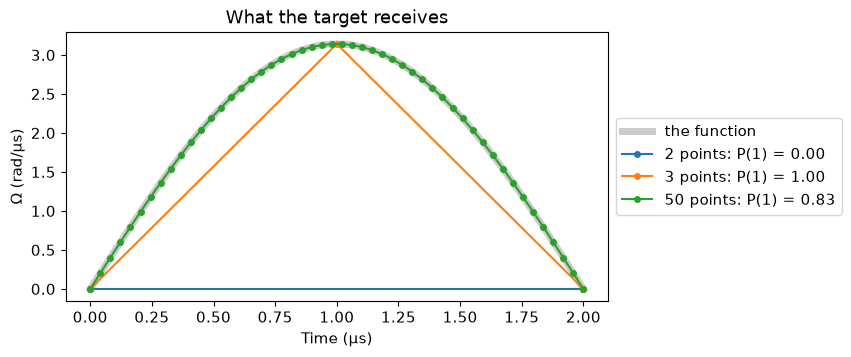

In [6]:
T = 2e-6
half_sine = ScalarOperator(lambda t: omega * np.sin(np.pi * t.real / T))
zero = ScalarOperator.const(0.0)

fine = np.linspace(0, T, 200)
plt.plot(fine * 1e6, omega * np.sin(np.pi * fine / T) / 1e6, color="0.8", lw=5, label="the function")
for points in (2, 3, 50):
    times = np.linspace(0, T, points)
    sampled = RydbergHamiltonian(atom_sites=[(0.0, 0.0)], amplitude=half_sine, phase=zero, delta_global=zero)
    p1 = cudaq.evolve(sampled, schedule=Schedule(times, ["t"]), shots_count=1000).probability("1")
    plt.plot(times * 1e6, omega * np.sin(np.pi * times / T) / 1e6, "o-", ms=4,
             label=f"{points} points: P(1) = {p1:.2f}")
    if points == 2:
        print(f"2 points: you predicted {predicted_two_points}, measured {p1:.2f}")
print(f"exact: P(1) = {np.sin(2) ** 2:.2f}")
plt.xlabel("Time (µs)")
plt.ylabel("Ω (rad/µs)")
plt.title("What the target receives")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

With 2 points the amplitude is zero at both ends, so nothing happens. With 3 points the pulse is a triangle of area $\pi$, a full flip. With 50 points it follows the sine. Real programs are usually short piecewise-linear schedules, as in the next notebooks; for smooth shapes, add points.

<details><summary><b>Check yourself:</b> A 1 µs pulse has a Gaussian amplitude peaking at 0.5 µs, with the schedule `[0, 1e-6]`. What does the target receive?</summary>

Only the two end values, joined by a straight line: the peak is lost. Add schedule points, at least one at 0.5 µs, more for the shape.

</details>

On a Pasqal QPU, the program becomes a [Pulser](https://docs.pasqal.com/pulser/) sequence with the same reading, so the GPU emulation predicts what the QPU is asked to do.

<details>
<summary><b>How the program becomes a Pulser sequence</b></summary>

There is one pulse per interval between schedule points, with a linear ramp (`RampWaveform`) for amplitude and detuning, or a `ConstantWaveform` when the two samples are equal, and the phase of the interval's first point. Times are rounded to nanoseconds (Pulser then rounds each pulse up to the device's clock period), and each interval must last at least the device's minimum pulse duration. The 3-point schedule above arrives as two pulses (Pulser units: ns and rad/µs):

```python
from pulser import Pulse
from pulser.waveforms import ConstantWaveform, RampWaveform

sequence.add(Pulse(RampWaveform(1000, 0.0, np.pi), ConstantWaveform(1000, 0.0), 0.0), "rydberg_global")
sequence.add(Pulse(RampWaveform(1000, np.pi, 0.0), ConstantWaveform(1000, 0.0), 0.0), "rydberg_global")
```

Pulser itself can also describe smooth shapes (for example interpolated waveforms), but CUDA-Q schedule points are always joined by straight lines, on the GPU and on the QPU alike.

</details>

## 4. Many programs at once: `evolve_async`

Now repeat the constant drive for durations from 0.1 to 3 µs. Theory says the atom is in `1` with probability $\sin^2(\Omega t/2)$.

`cudaq.evolve_async` takes the same arguments as `evolve` but returns a future immediately. We launch all 30 programs, then collect the results. On the GPU they run one after another in the background; on a QPU all jobs are queued at once instead of waiting for each other. `cudaq.set_random_seed` makes the emulator's shots reproducible.

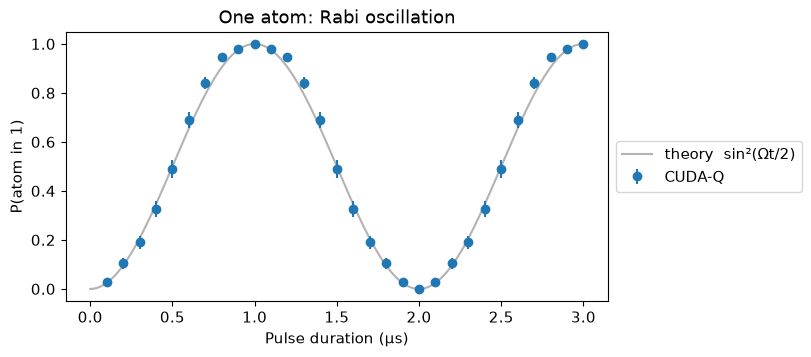

In [7]:
cudaq.set_random_seed(7)
durations = np.round(np.arange(1, 31) * 0.1e-6, 9)  # 0.1 ... 3.0 µs; rounding drops float noise like 3.0000000000000004e-07


def constant_drive(sites):
    """Return a constant drive with no detuning for the given atoms."""
    return RydbergHamiltonian(atom_sites=sites, amplitude=ScalarOperator.const(omega), phase=zero, delta_global=zero)


def scan(sites, outcomes, shots=200):
    """Run the constant drive for every duration and return P(outcomes) with its standard error."""
    futures = [cudaq.evolve_async(constant_drive(sites), schedule=Schedule([0.0, d], ["t"]), shots_count=shots)
               for d in durations]
    return np.array([probability(dict(f.get().items()), outcomes) for f in futures]).T


one_atom = [(0.0, 0.0)]
p, err = scan(one_atom, ["1"])
t = np.linspace(0, 3, 300)
plt.plot(t, np.sin(omega * t * 1e-6 / 2) ** 2, color="0.7", label="theory  sin²(Ωt/2)")
plt.errorbar(durations * 1e6, p, yerr=err, fmt="o", label="CUDA-Q")
plt.xlabel("Pulse duration (µs)")
plt.ylabel("P(atom in 1)")
plt.title("One atom: Rabi oscillation")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

The dots follow the curve within their error bars, which come from the finite number of shots (200 per point).

## 5. Two atoms: independent, then blockaded

Place two atoms 14 µm apart. Their interaction $U = C_6/r^6$ is small compared with the drive, so each atom should oscillate on its own, and both are in `1` with probability $\sin^4(\Omega t/2)$.

The scale that separates "far" from "close" is the **blockade radius** $R_b$, where the interaction equals the drive: $C_6/R_b^6 = \Omega$. It depends on $C_6$, so on the device. The shaded discs below have radius $R_b/2$: they overlap when two atoms are closer than $R_b$.

Blockade radius at level 60 and Ω = π rad/µs: 8.1 µm
At 14 µm: U/Ω = 0.04


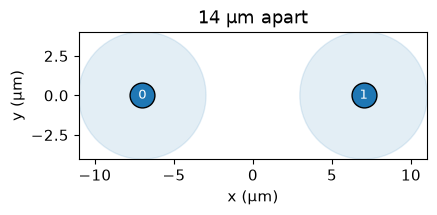

In [8]:
def pair(distance_um):
    """Place two atoms on the x axis, centred on the origin."""
    return [(-distance_um * 0.5e-6, 0.0), (distance_um * 0.5e-6, 0.0)]


radius = draw.blockade_radius(C6, omega)
print(f"Blockade radius at level 60 and Ω = π rad/µs: {radius:.1f} µm")
print(f"At 14 µm: U/Ω = {C6 / 14e-6 ** 6 / omega:.2f}")
draw.register(pair(14), radius_um=radius, title="14 µm apart")
plt.show()

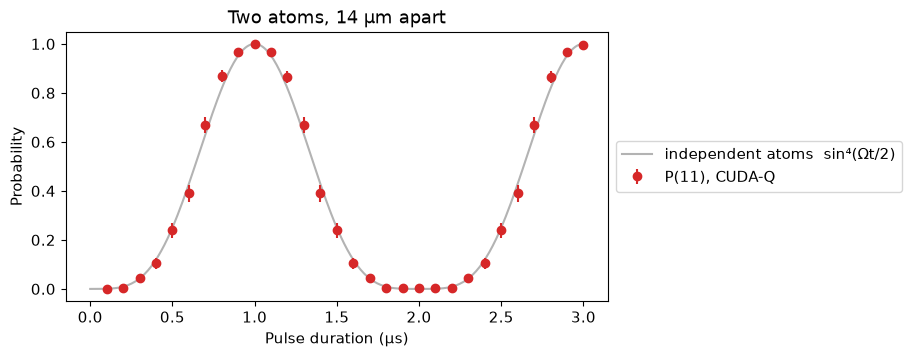

In [9]:
p11, err11 = scan(pair(14), ["11"])
s = np.sin(omega * t * 1e-6 / 2) ** 2
plt.plot(t, s ** 2, color="0.7", label="independent atoms  sin⁴(Ωt/2)")
plt.errorbar(durations * 1e6, p11, yerr=err11, fmt="o", color="tab:red", label="P(11), CUDA-Q")
plt.xlabel("Pulse duration (µs)")
plt.ylabel("Probability")
plt.title("Two atoms, 14 µm apart")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

Now move the atoms to 5 µm. $U \gg \Omega$: exciting the second atom costs far more energy than the laser provides.

In [10]:
# Predict: the largest P(11) over the whole scan at 5 µm? At 14 µm it reached 1.
predicted_p11 = None

At 5 µm: U/Ω = 18


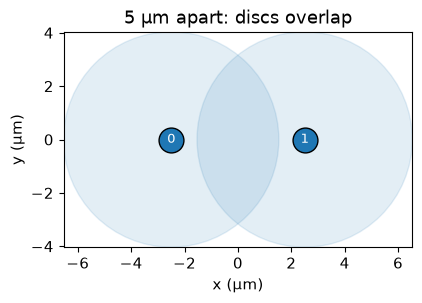

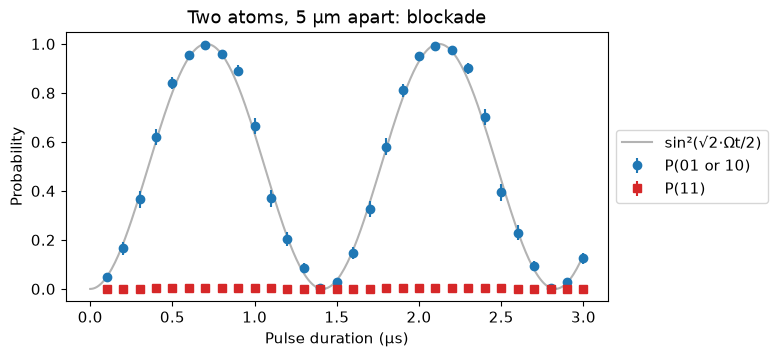

largest P(11): you predicted None, measured 0.01


In [11]:
print(f"At 5 µm: U/Ω = {C6 / 5e-6 ** 6 / omega:.0f}")
draw.register(pair(5), radius_um=radius, title="5 µm apart: discs overlap")
plt.show()

p11, err11 = scan(pair(5), ["11"])
p1, err1 = scan(pair(5), ["01", "10"])
plt.plot(t, np.sin(np.sqrt(2) * omega * t * 1e-6 / 2) ** 2, color="0.7", label="sin²(√2·Ωt/2)")
plt.errorbar(durations * 1e6, p1, yerr=err1, fmt="o", label="P(01 or 10)")
plt.errorbar(durations * 1e6, p11, yerr=err11, fmt="s", color="tab:red", label="P(11)")
plt.xlabel("Pulse duration (µs)")
plt.ylabel("Probability")
plt.title("Two atoms, 5 µm apart: blockade")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()
print(f"largest P(11): you predicted {predicted_p11}, measured {p11.max():.2f}")

`11` never appears: the pair shares **a single excitation**. It oscillates between `00` and the entangled state $(|01\rangle + |10\rangle)/\sqrt{2}$, $\sqrt{2}$ times faster than a single atom. The blockade is the key resource of neutral-atom computing; the next notebook uses it to solve a graph problem.

### Where does the blockade stop?

Fix the pulse to a collective π pulse, $t = \pi/(\sqrt{2}\,\Omega) \approx 708$ ns (rounded to the 4 ns clock of the device), which fully excites a blockaded pair into one shared excitation, and vary the distance across $R_b$.

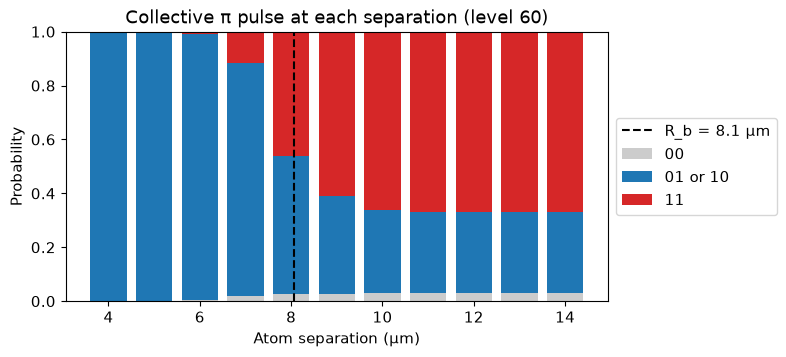

In [12]:
pi_pulse = round(np.pi / (np.sqrt(2) * omega) / 4e-9) * 4e-9
distances = list(range(4, 15))
futures = [cudaq.evolve_async(constant_drive(pair(d)), schedule=Schedule([0.0, pi_pulse], ["t"]), shots_count=500)
           for d in distances]
sweep = [dict(f.get().items()) for f in futures]

none, one, both = (np.array([probability(c, o)[0] for c in sweep]) for o in (["00"], ["01", "10"], ["11"]))
plt.bar(distances, none, color="0.8", label="00")
plt.bar(distances, one, bottom=none, color="tab:blue", label="01 or 10")
plt.bar(distances, both, bottom=none + one, color="tab:red", label="11")
plt.axvline(radius, color="k", ls="--", label=f"R_b = {radius:.1f} µm")
plt.xlabel("Atom separation (µm)")
plt.ylabel("Probability")
plt.title("Collective π pulse at each separation (level 60)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

Inside the blockade radius the pair ends in one shared excitation (blue). Beyond it, `11` appears and approaches the independent-atom value $\sin^4(\Omega t/2) \approx 0.65$: this pulse is a π pulse for the pair, not for each atom on its own.

<details><summary><b>Check yourself:</b> Double the drive to $\Omega = 2\pi$ rad/µs. Is the blockade radius larger or smaller than 8.1 µm?</summary>

Smaller: $C_6/R_b^6 = \Omega$ gives $R_b \propto \Omega^{-1/6}$, so $8.1 / 2^{1/6} \approx 7.2$ µm. A stronger drive can overcome a weaker interaction.

</details>

### Explore: move the atoms yourself

Each two-atom program takes a few milliseconds on the GPU, so it can follow a slider. Drag the separation across $R_b$ and change the pulse length. The sliders need a running notebook; a saved copy shows nothing here.

In [13]:
import ipywidgets as widgets


def explore(distance_um, duration_ns):
    """Run the constant drive on a pair and plot the three outcomes."""
    result = cudaq.evolve(constant_drive(pair(distance_um)), schedule=Schedule([0.0, duration_ns * 1e-9], ["t"]), shots_count=500)
    counts = dict(result.items())
    outcomes = {"00": ["00"], "01 or 10": ["01", "10"], "11": ["11"]}
    plt.bar(outcomes.keys(), [probability(counts, o)[0] for o in outcomes.values()], color=["0.8", "tab:blue", "tab:red"])
    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.title(f"{distance_um:g} µm apart ({'inside' if distance_um < radius else 'outside'} R_b = {radius:.1f} µm), {duration_ns} ns")
    plt.show()


_ = widgets.interact(
    explore,
    distance_um=widgets.FloatSlider(value=6.0, min=3.0, max=15.0, step=0.5, continuous_update=False, description="µm"),
    duration_ns=widgets.IntSlider(value=708, min=100, max=3000, step=4, continuous_update=False, description="ns"),
)

interactive(children=(FloatSlider(value=6.0, continuous_update=False, description='µm', max=15.0, min=3.0, ste…

### Your turn: three atoms

Put three atoms on a line, 5 µm apart, and drive them for 1 µs. Neighbours are inside $R_b$; the two ends, 10 µm apart, are not. **Predict** how many atoms can be excited at once, then run. Then try a spacing of 3.5 µm, where all three are inside $R_b$.

In [14]:
spacing_um = 5.0
line = [(-spacing_um * 1e-6, 0.0), (0.0, 0.0), (spacing_um * 1e-6, 0.0)]
counts = dict(cudaq.evolve(constant_drive(line), schedule=Schedule([0.0, 1e-6], ["t"]), shots_count=1000).items())
excited = {k: sum(n for b, n in counts.items() if b.count("1") == k) for k in range(4)}
print("shots with 0, 1, 2, 3 atoms excited:", list(excited.values()))
print("bitstrings:", dict(sorted(counts.items())))

shots with 0, 1, 2, 3 atoms excited: [177, 326, 497, 0]
bitstrings: {'000': 177, '001': 66, '010': 201, '100': 59, '101': 497}


<details><summary><b>Answer</b></summary>

At 5 µm, at most two atoms are excited, and only as `101`: the ends are outside each other's blockade radius, neighbours are inside it, so `110`, `011` and `111` (almost) never appear. At 3.5 µm all three blockade each other and the line shares at most one excitation: `100`, `010`, `001` or none.

</details>

## 6. The same program on a QPU

Nothing in the program refers to the GPU. Only `set_target` changes:

| Target | Runs on |
|---|---|
| `cudaq.set_target("pasqal", emulate=True, emulation_rydberg_c6=...)` | Ideal emulation on your GPU |
| `cudaq.set_target("pasqal", machine="qrmi")` | The QPU your HPC scheduler assigned to the job, through QRMI |
| `cudaq.set_target("pasqal", machine="EMU_FREE")` | A Pasqal Cloud machine (needs `PASQAL_AUTH_TOKEN`, `PASQAL_PROJECT_ID`) |

On the QPU targets `emulation_rydberg_c6` has no effect: the atoms bring their own $C_6$. Before comparing a GPU run with a QPU run, emulate with **that device's** $C_6$, and keep the positions and pulses within its limits (minimum distance, maximum $\Omega$ and $\Delta$, layout).

The QRMI route only works inside a scheduler job that holds a QPU. [Step 04](../04-slurm/README.md) runs this distance sweep as a GPU job, then a QPU job, then a CPU comparison. Optional [step 06](../06-cpp/README.md) writes it in C++.

<details><summary><b>Check yourself:</b> What do you change in this notebook to run the distance sweep on the QPU your Slurm job holds?</summary>

One line: `cudaq.set_target("pasqal", machine="qrmi")`. The positions, pulses and `evolve` calls stay the same. Keep them within the device's limits.

</details>

## Key points

- An analog program is **atom positions plus pulses** ($\Omega$, $\Delta$, $\phi$): a `RydbergHamiltonian`, run with `cudaq.evolve` over a `Schedule`.
- The emulator needs the device's **$C_6$**; the QPU has its own. All length scales follow $C_6^{1/6}$.
- CUDA-Q samples your pulse functions **only at the schedule times**; amplitude and detuning are linear in between, the phase is held.
- `evolve_async` launches many programs at once; `set_random_seed` makes emulated shots reproducible.
- Within the **blockade radius**, two atoms share one excitation and become entangled.

<div class="alert alert-success">

**To go further**

- Rerun section 5 with the level-70 $C_6$ (change `C6` and `set_target` in section 1). Where does the blockade stop now?
- Double `omega`. How do the oscillation and the blockade radius change?
- Give the 14 µm pair a phase jump: `phase=ScalarOperator(lambda t: 0.0 if t.real < 0.5e-6 else np.pi)` with schedule `[0, 0.5e-6, 1e-6]`. What happens to the second half of the pulse?

</div>